# 02 — Preprocessing & Feature Engineering
**Ames Housing Dataset**

Goal: turn the raw data into a clean, fully numeric matrix ready for modeling, applying the decisions taken in `01_eda.ipynb`.

**Design decision:** every transformation lives inside a single scikit-learn `Pipeline`, defined in [`src/preprocessing.py`](../src/preprocessing.py). This way:
- statistics (medians, skewness, scaling, categories) are learned **only from the training data**, avoiding *data leakage* during cross-validation;
- the exact same transformations are applied to the test set and to any new house at prediction time.

This notebook walks through each step and checks that it does what we expect.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import set_config
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline

from src.preprocessing import (
    GroupMedianImputer, add_features, build_preprocessor,
    encode_ordinals, fill_structural_missing, remove_outliers,
)

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 120})
set_config(display='diagram')

In [2]:
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')
print('Train:', train.shape, '| Test:', test.shape)

Train: (1460, 81) | Test: (1459, 80)


## 1. Outliers and target

- Remove the 2 outliers found in the EDA (>4,000 sq ft sold for <$200k). Only from **train**: we never drop rows from the test set.
- Model `log1p(SalePrice)` instead of `SalePrice` (skewness 1.88 → 0.12). Predictions will be converted back with `expm1`.

In [3]:
train = remove_outliers(train)
print('Train after removing outliers:', train.shape)

y = np.log1p(train.pop('SalePrice'))
X = train
y.describe().round(3)

Train after removing outliers: (1458, 81)


count    1458.000
mean       12.024
std         0.400
min        10.460
25%        11.775
50%        12.002
75%        12.274
max        13.534
Name: SalePrice, dtype: float64

## 2. Step-by-step walkthrough

### 2.1 Structural missing values
For most features NaN means *the house doesn't have it* (no pool, no garage, no basement...), according to `data_description.txt`. These are filled with `"None"` (categorical) or `0` (numeric). `GarageYrBlt` is filled with `YearBuilt`, since a year 0 would be meaningless.

In [4]:
def missing_report(df):
    m = df.isna().sum()
    return m[m > 0].sort_values(ascending=False)

before = missing_report(pd.concat([X, test]))
after = missing_report(fill_structural_missing(pd.concat([X, test])))
print(f'Features with NaN (train + test): {len(before)} before → {len(after)} after\n')
print('Remaining (handled by later steps):')
print(after.to_string())

Features with NaN (train + test): 34 before → 8 after

Remaining (handled by later steps):
LotFrontage    486
MSZoning         4
Utilities        2
Exterior1st      1
Exterior2nd      1
Electrical       1
KitchenQual      1
SaleType         1


What remains is `LotFrontage` (next step) plus a handful of isolated NaNs (1–4 rows per feature, mostly in the **test** set). Those are imputed later with the median / most frequent value, learned from train.

### 2.2 `LotFrontage` — median by neighborhood
`LotFrontage` (17.7% missing) is genuinely unknown. Lot sizes are similar within a neighborhood, so the neighborhood median is a better guess than the global median. `GroupMedianImputer` learns these medians in `fit` (train only).

In [5]:
imp = GroupMedianImputer('LotFrontage', 'Neighborhood').fit(X)
print(f'Global median: {imp.global_median_:.0f} ft')
print('Median by neighborhood (summary):')
imp.group_medians_.describe().round(1)

Global median: 69 ft
Median by neighborhood (summary):


count    25.0
mean     62.0
std      20.6
min      21.0
25%      60.0
50%      66.5
75%      73.5
max      91.0
Name: LotFrontage, dtype: float64

### 2.3 Ordinal encoding
Quality ratings have a natural order (`Po < Fa < TA < Gd < Ex`). Mapping them to integers (1–5, with `None` = 0) keeps that order, which one-hot encoding would lose, and uses a single column instead of six.

In [6]:
cols = ['ExterQual', 'KitchenQual', 'BsmtQual', 'GarageFinish']
filled = fill_structural_missing(X)
pd.concat([filled[cols].head(), encode_ordinals(filled)[cols].head()], axis=1, keys=['raw', 'encoded'])

raw                                     encoded                       \
  ExterQual KitchenQual BsmtQual GarageFinish ExterQual KitchenQual BsmtQual   
0        Gd          Gd       Gd          RFn       4.0         4.0      4.0   
1        TA          TA       Gd          RFn       3.0         3.0      4.0   
2        Gd          Gd       Gd          RFn       4.0         4.0      4.0   
3        TA          Gd       TA          Unf       3.0         4.0      3.0   
4        Gd          Gd       Gd          RFn       4.0         4.0      4.0   

                
  GarageFinish  
0          2.0  
1          2.0  
2          2.0  
3          1.0  
4          2.0

### 2.4 Feature engineering
New features based on domain knowledge:

| Feature | Definition | Why |
|---|---|---|
| `TotalSF` | basement + 1st + 2nd floor area | Buyers value total space |
| `TotalBath` | full + 0.5 × half baths (incl. basement) | Single bathroom count |
| `TotalPorchSF` | sum of all porch / deck areas | Combines 5 sparse features |
| `HouseAge`, `YearsSinceRemod` | `YrSold` − build / remodel year | Age at the time of sale |
| `QualxSF` | `OverallQual` × `GrLivArea` | Interaction of the two strongest predictors |
| `Has*` flags | pool, garage, basement, fireplace, 2nd floor | Presence vs. absence |

`MSSubClass` and `MoSold` are numeric codes that represent categories, so they are cast to strings. `Id` and `Utilities` (constant in practice) are dropped.

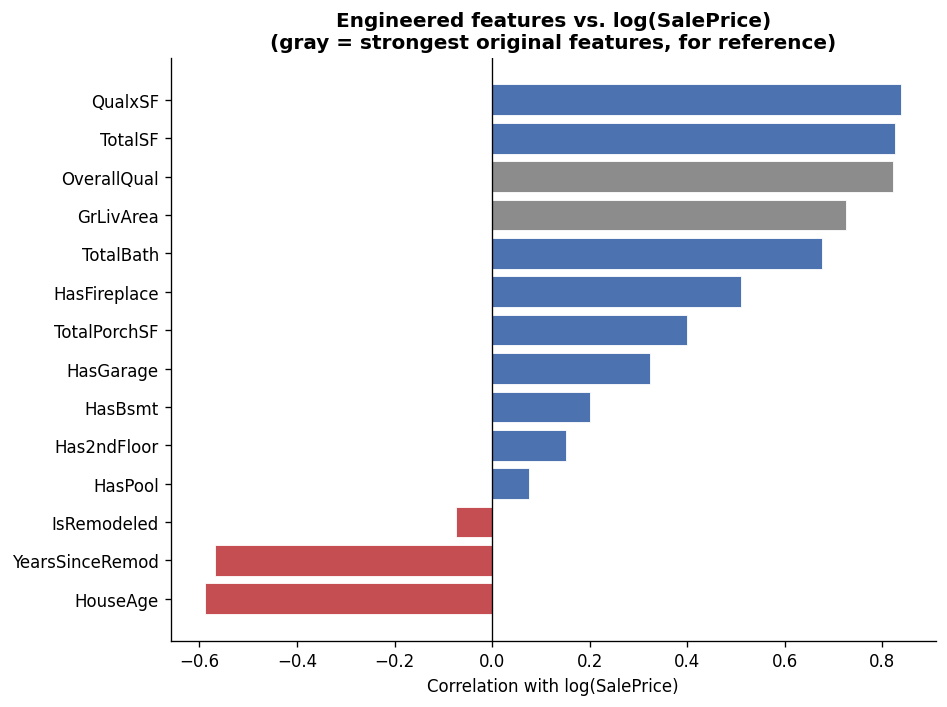

QualxSF            0.838
TotalSF            0.825
OverallQual        0.821
GrLivArea          0.725
TotalBath          0.677
HasFireplace       0.510
TotalPorchSF       0.400
HasGarage          0.323
HasBsmt            0.200
Has2ndFloor        0.151
HasPool            0.077
IsRemodeled       -0.074
YearsSinceRemod   -0.569
HouseAge          -0.588


In [7]:
X_fe = add_features(encode_ordinals(fill_structural_missing(X)))
new_feats = ['QualxSF', 'TotalSF', 'TotalBath', 'HouseAge', 'YearsSinceRemod', 'TotalPorchSF',
             'HasFireplace', 'HasGarage', 'IsRemodeled', 'Has2ndFloor', 'HasBsmt', 'HasPool']
compare = ['OverallQual', 'GrLivArea']
corr = X_fe[new_feats + compare].corrwith(y).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#8C8C8C' if f in compare else ('#C44E52' if v < 0 else '#4C72B0') for f, v in corr.items()]
ax.barh(corr.index, corr.values, color=colors, edgecolor='white', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Correlation with log(SalePrice)')
ax.set_title('Engineered features vs. log(SalePrice)\n(gray = strongest original features, for reference)', fontweight='bold')
plt.tight_layout()
plt.show()

print(corr.sort_values(ascending=False).round(3).to_string())

### 2.5 Skewed numeric features
Like the target, many area features are right-skewed. `SkewCorrector` applies `log1p` to non-negative columns with skewness > 0.75 (measured on train). This mainly helps linear models; tree-based models are insensitive to it.

In [8]:
num = X_fe.select_dtypes('number')
skew = num.skew().sort_values(ascending=False)
print(f'{(skew > 0.75).sum()} of {num.shape[1]} numeric features have skewness > 0.75')
skew.head(10).round(2)

28 of 62 numeric features have skewness > 0.75


MiscVal         24.46
PoolQC          17.55
PoolArea        15.95
HasPool         15.51
LotArea         12.57
3SsnPorch       10.30
LowQualFinSF     9.00
KitchenAbvGr     4.48
BsmtFinSF2       4.25
ScreenPorch      4.12
dtype: float64

## 3. Full pipeline

All the steps above, plus:
- **numeric**: median imputation → skew correction → `StandardScaler`
- **categorical**: most-frequent imputation → `OneHotEncoder(handle_unknown='ignore')` (categories unseen in train are ignored at prediction time instead of crashing)

In [9]:
preprocessor = build_preprocessor()
preprocessor

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('structural_na', ...), ('lot_frontage', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function fil...001DD7FD4B600>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword argum

In [10]:
X_train = preprocessor.fit_transform(X)   # learn from train
X_test = preprocessor.transform(test)     # only apply to test

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('NaN in train:', X_train.isna().sum().sum(), '| NaN in test:', X_test.isna().sum().sum())
print('Same columns, same order:', (X_train.columns == X_test.columns).all())

skewed = preprocessor.named_steps['columns'].named_transformers_['num'].named_steps['unskew'].skewed_cols_
print(f'\nlog1p applied to {len(skewed)} numeric features')

X_train: (1458, 270) | X_test: (1459, 270)
NaN in train: 0 | NaN in test: 0
Same columns, same order: True

log1p applied to 28 numeric features


## 4. Sanity check

A quick Ridge regression to confirm the pipeline produces a sensible, leakage-free result. The preprocessor goes **inside** `cross_val_score`, so in every fold it is fitted only on that fold's training part.

This is not the final model (that's step 6), just a check that the preprocessing works.

In [11]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
model = make_pipeline(build_preprocessor(), Ridge(alpha=10))
scores = -cross_val_score(model, X, y, cv=cv, scoring='neg_root_mean_squared_error')

print(f'Ridge CV RMSE (log scale): {scores.mean():.4f} ± {scores.std():.4f}')
print(f'≈ typical error of {np.expm1(scores.mean()) * 100:.1f}% on the sale price')

Ridge CV RMSE (log scale): 0.1129 ± 0.0075
≈ typical error of 12.0% on the sale price


## 5. Summary

| Step | Decision |
|---|---|
| Outliers | 2 rows removed from train (Ids 524, 1299) |
| Target | `log1p(SalePrice)` |
| Structural NaN | `"None"` / `0` in 24 features; `GarageYrBlt` ← `YearBuilt`; `Functional` ← `Typ` |
| `LotFrontage` | Median by `Neighborhood`, learned on train |
| Ordinal features | 16 features mapped to ordered integers |
| New features | 12 (`TotalSF`, `TotalBath`, `HouseAge`, `QualxSF`, ...) |
| Skewed features | `log1p` where skewness > 0.75 |
| Scaling / encoding | `StandardScaler` + `OneHotEncoder` → **270 features**, 0 NaN |
| Sanity check | Ridge CV RMSE ≈ **0.113** (log scale) |

**Next:** `03_modeling.ipynb`: baseline, linear models, tree-based models and ensemble, compared with 5-fold cross-validation.